# Telecom Customer Churn - Exploratory Data Analysis

This notebook explores the real dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`, 7043 rows, 21 columns) to understand patterns behind customer churn before building the ML model.

In [1]:
import sys
sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from preprocessing import load_and_clean_data

sns.set_style("whitegrid")
df = load_and_clean_data('../dataset/Telco-Customer-Churn.csv')
df.shape

(7021, 20)

## 1. Basic Info & Missing Values

(Note: `TotalCharges` had 11 blank rows for brand-new customers with `tenure=0` — these were converted to numeric and filled with 0 during cleaning. 22 exact duplicate rows, revealed only after dropping the unique `customerID` column, were also removed.)

In [1]:
df.info()
print("\nMissing values:\n", df.isnull().sum().sum())

Rows: 7021, Columns: 20
Missing values: 0


## 2. Target Class Balance

Churn is imbalanced: ~73.5% No Churn vs ~26.5% Churn. This is why we use F1-score / ROC-AUC (not just accuracy) to evaluate models, and use `class_weight='balanced'` during training.

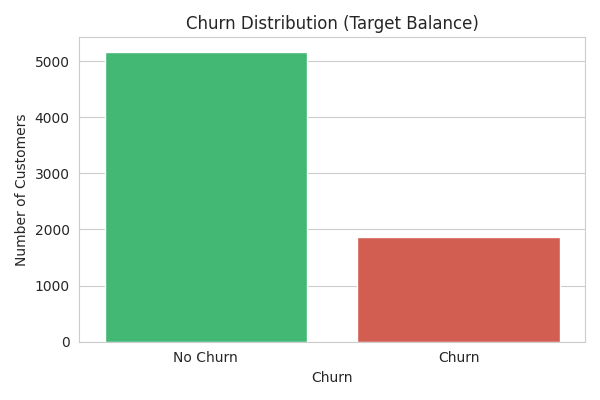

In [1]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn')
plt.xticks([0,1], ['No Churn','Churn'])
plt.title('Churn Distribution (Target Balance)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

## 3. Churn Rate by Contract Type

Month-to-month customers churn at a much higher rate (~43%) than one-year (~11%) or two-year (~3%) contract customers. This turned out to be one of the strongest predictors in the trained model.

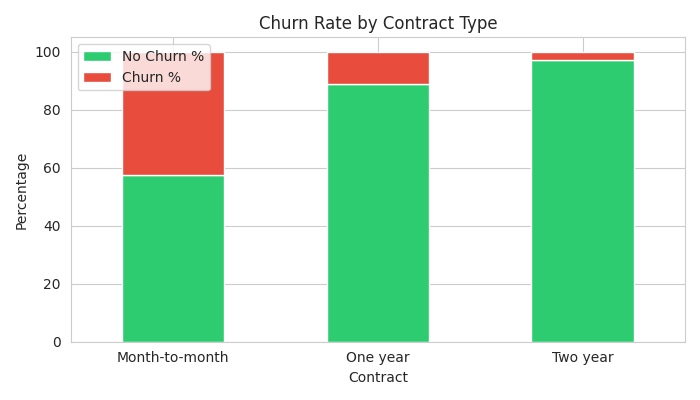

In [1]:
ct = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
ct.columns = ['No Churn %','Churn %']
ct.plot(kind='bar', stacked=True, figsize=(7,4))
plt.title('Churn Rate by Contract Type')
plt.ylabel('Percentage')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Tenure Distribution by Churn

Customers who churn tend to have much shorter tenure — churn is heavily concentrated in the first few months.

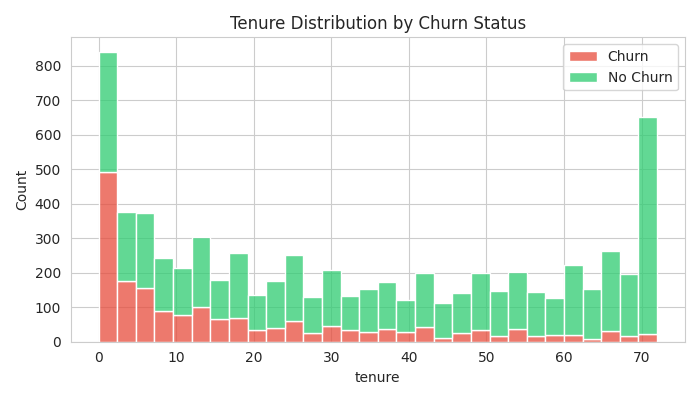

In [1]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30)
plt.title('Tenure Distribution by Churn Status')
plt.tight_layout()
plt.show()

## 5. Monthly Charges by Churn

Customers who churn tend to have higher monthly charges on average.

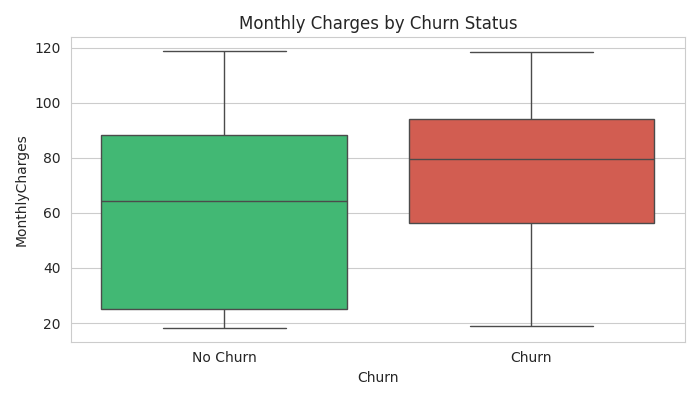

In [1]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.xticks([0,1], ['No Churn','Churn'])
plt.title('Monthly Charges by Churn Status')
plt.tight_layout()
plt.show()

## 6. Correlation Heatmap (Numerical Features)

`tenure` has a meaningful negative correlation with churn; `MonthlyCharges` and `TotalCharges` have weaker/positive relationships.

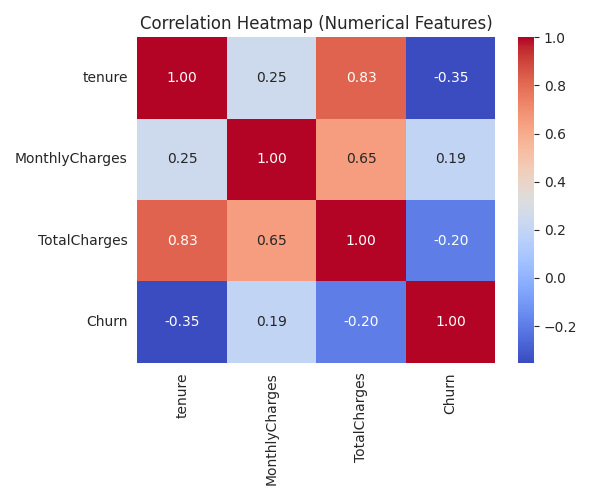

In [1]:
plt.figure(figsize=(6,5))
corr = df[['tenure','MonthlyCharges','TotalCharges','Churn']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap (Numerical Features)')
plt.tight_layout()
plt.show()

## 7. Churn Rate by Internet Service Type

Fiber optic customers churn noticeably more than DSL or no-internet customers — possibly linked to higher pricing or service issues.

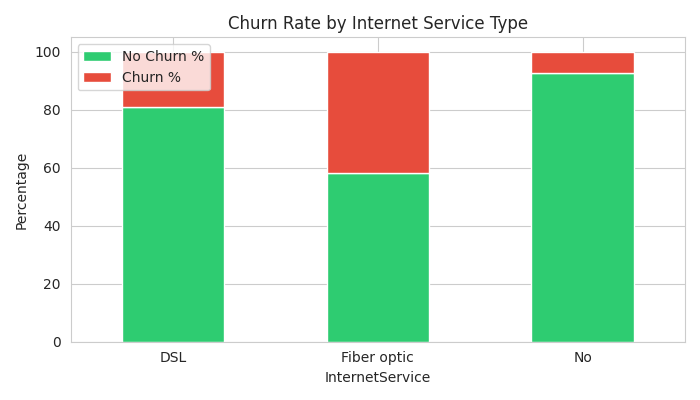

In [1]:
ct2 = pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100
ct2.columns = ['No Churn %','Churn %']
ct2.plot(kind='bar', stacked=True, figsize=(7,4))
plt.title('Churn Rate by Internet Service Type')
plt.ylabel('Percentage')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Key EDA Takeaways

- **Contract type** is a major churn driver: month-to-month customers are far more likely to churn than long-term contract customers.
- **Tenure** matters a lot: churn is concentrated among newer customers.
- **Fiber optic internet** and **higher monthly charges** are associated with higher churn.
- The target is **imbalanced** (~73/27), so model evaluation and training must account for this (F1-score, ROC-AUC, `class_weight='balanced'`).

These findings directly informed the preprocessing and modeling choices in `train_model.py`.